<a href="https://colab.research.google.com/github/Mithun-J/Assessment-supervised-learning-by-mithun-/blob/main/Assessment_supervised_learning_by_mithun_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bank Marketing: Term Deposit Subscription Prediction


## 1. Data Understanding and Exploratory Analysis

### 1.1 Load the data and inspect it

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/DSAB13/Colab Notebooks/Dataset/bank_marketing_assessment_dataset.csv')

print('Shape:', df.shape)
print(" ")
print('Columns:', df.columns.tolist())

Shape: (600, 14)
 
Columns: ['customer_age', 'job', 'marital_status', 'education', 'account_balance', 'housing_loan', 'personal_loan', 'contact_type', 'contact_month', 'campaign_contacts', 'previous_contacts', 'engagement_score', 'annual_income_estimate', 'subscribed']


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_age            600 non-null    int64  
 1   job                     600 non-null    object 
 2   marital_status          600 non-null    object 
 3   education               585 non-null    object 
 4   account_balance         588 non-null    float64
 5   housing_loan            600 non-null    object 
 6   personal_loan           600 non-null    object 
 7   contact_type            591 non-null    object 
 8   contact_month           600 non-null    object 
 9   campaign_contacts       600 non-null    int64  
 10  previous_contacts       600 non-null    int64  
 11  engagement_score        600 non-null    int64  
 12  annual_income_estimate  600 non-null    int64  
 13  subscribed              600 non-null    object 
dtypes: float64(1), int64(5), object(8)
memory 

In [27]:
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [28]:
df.describe()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate
count,600.000000,588.000000,600.000000,600.000000,600.000000,600.0000
mean,38.208333,1535.037415,5.566667,1.015000,4.451667,31805.3650
std,15.387426,2366.916896,2.020485,1.582914,2.938603,17264.0821
min,18.000000,-5418.000000,3.000000,0.000000,1.000000,12000.0000
25%,26.000000,-24.750000,4.000000,0.000000,1.000000,16112.5000
50%,34.000000,1589.500000,5.000000,0.000000,4.000000,29156.0000
75%,49.000000,3042.750000,7.000000,2.000000,7.000000,43444.0000
max,75.000000,9365.000000,13.000000,8.000000,10.000000,108930.0000


### 1.2 Missing values and duplicates

In [29]:
print('Missing values:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

Missing values:
customer_age               0
job                        0
marital_status             0
education                 15
account_balance           12
housing_loan               0
personal_loan              0
contact_type               9
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64

Duplicate rows: 0


Only education (15), account_balance (12) and contact_type (9) have missing values, and there are no duplicate rows. These will be filled later, after the train-test split, to avoid data leakage.

### 1.3 Target distribution

subscribed
no     426
yes    174
Name: count, dtype: int64

subscribed
no     71.0
yes    29.0
Name: proportion, dtype: float64


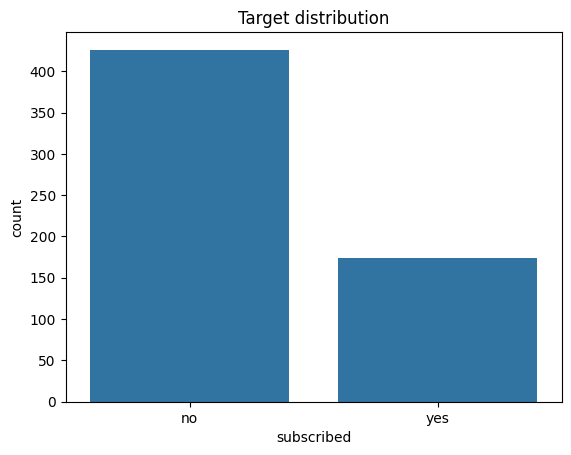

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df['subscribed'].value_counts())
print("")
print(df['subscribed'].value_counts(normalize=True).round(3) * 100)

sns.countplot(x='subscribed', data=df)
plt.title('Target distribution')
plt.show()

About 71% of customers did not subscribe and 29% did, so the data is **imbalanced**. Accuracy alone can be misleading, so precision, recall and F1 are also used.

### 1.4 Useful observations

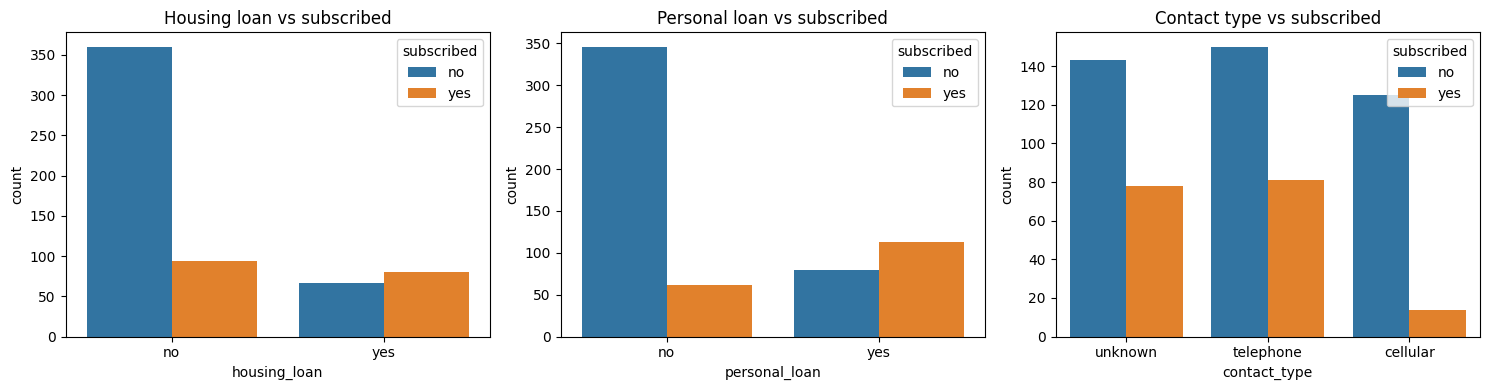

In [31]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.countplot(x='housing_loan', hue='subscribed', data=df)
plt.title('Housing loan vs subscribed')

plt.subplot(1, 3, 2)
sns.countplot(x='personal_loan', hue='subscribed', data=df)
plt.title('Personal loan vs subscribed')

plt.subplot(1, 3, 3)
sns.countplot(x='contact_type', hue='subscribed', data=df)
plt.title('Contact type vs subscribed')

plt.tight_layout()
plt.show()

In [32]:
# Subscription rate (%) for each group
for col in ['housing_loan', 'personal_loan', 'contact_type']:
    print((df.groupby(col)['subscribed'].apply(lambda s: (s == 'yes').mean() * 100)).round(1))
    print()

housing_loan
no     20.7
yes    54.8
Name: subscribed, dtype: float64

personal_loan
no     15.0
yes    58.5
Name: subscribed, dtype: float64

contact_type
cellular     10.1
telephone    35.1
unknown      35.3
Name: subscribed, dtype: float64



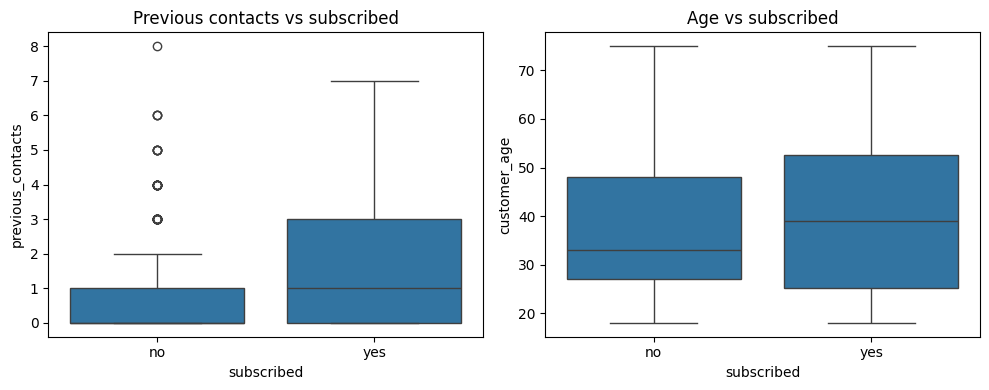

In [33]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x='subscribed', y='previous_contacts', data=df)
plt.title('Previous contacts vs subscribed')

plt.subplot(1, 2, 2)
sns.boxplot(x='subscribed', y='customer_age', data=df)
plt.title('Age vs subscribed')

plt.tight_layout()
plt.show()

**Observations:**
1. Customers with a **housing loan**  or a **personal loan**  subscribe much more often than customers without one .
2. Customers contacted by **cellular** subscribe far less (about 10%) than those contacted by telephone or "unknown" .
3. Subscribers have had more **previous contacts** with the bank than non-subscribers.

## 2. Data Preparation and Feature Engineering

### 2.1 Separate X and y
The target is converted to numbers: `yes` = 1 and `no` = 0. `subscribed` is not used as an input feature.

In [34]:
y = df['subscribed'].map({'no': 0, 'yes': 1})
X = df.drop(columns='subscribed')

print(X.shape, y.shape)

(600, 13) (600,)


### 2.2 Train-test split (80:20)

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Subscribed share in train:', round(y_train.mean(), 3))
print('Subscribed share in test :', round(y_test.mean(), 3))

Train: (480, 13)  Test: (120, 13)
Subscribed share in train: 0.29
Subscribed share in test : 0.292


`stratify=y` keeps the same yes/no ratio in both the training and test sets.

### 2.3 Handling missing values (fillna)
To avoid data leakage, the fill values (median and mode) are calculated only from the training set. The same values are then used to fill the training set and the test set. The test set is never used to calculate anything.

- Numerical column (account_balance) → filled with the median
- Categorical columns (education, contact_type) → filled with the mode (most frequent value)

In [36]:
# Make copies so the original splits stay safe
X_train = X_train.copy()
X_test = X_test.copy()

# Numerical: median from the training set
balance_median = X_train['account_balance'].median()
X_train['account_balance'] = X_train['account_balance'].fillna(balance_median)
X_test['account_balance'] = X_test['account_balance'].fillna(balance_median)

# Categorical: mode from the training set
for col in ['education', 'contact_type']:
    mode_value = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

print('Missing values in train:', X_train.isnull().sum().sum())
print('Missing values in test :', X_test.isnull().sum().sum())

Missing values in train: 0
Missing values in test : 0


### 2.4 Encoding categorical features
Categorical columns are converted to 0/1 columns with pd.get_dummies (one-hot encoding). drop_first=True removes one column per feature, so a yes/no feature becomes one column.

The test set must have exactly the same columns as the training set

In [37]:
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)

# Make the test columns the same as the train columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print('Train shape:', X_train.shape)
print('Test shape :', X_test.shape)
X_train.head()

Train shape: (480, 24)
Test shape : (120, 24)


,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,job_blue-collar,job_management,job_retired,job_services,...,education_tertiary,housing_loan_yes,personal_loan_yes,contact_type_telephone,contact_type_unknown,contact_month_jul,contact_month_jun,contact_month_may,contact_month_nov,contact_month_oct
443,75,-2735.0,6,0,10,56065,1,0,0,0,...,0,1,0,0,0,0,0,0,1,0
189,31,-1845.0,5,0,1,12000,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
384,30,3776.0,4,0,4,16125,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
442,48,-584.0,5,0,2,29064,0,1,0,0,...,0,0,0,0,1,1,0,0,0,0
563,24,4507.0,4,0,8,68524,0,1,0,0,...,0,0,0,0,1,0,0,0,1,0


### 2.5 Scaling
Scaling is done with `StandardScaler`. It is placed **inside the model pipeline** (next section), so the mean and standard deviation are learned only from the training data when the model is fitted. The test data is only transformed.

## 3. Model Building

### 3.1 Logistic Regression

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_model = Pipeline([('scaler', StandardScaler()),('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))])

log_model.fit(X_train, y_train);

### 3.2 Random Forest

In [39]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([('scaler', StandardScaler()),('model', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42))])

rf_model.fit(X_train, y_train);

## 4. Model Evaluation and Comparison

### 4.1 Metrics on the test set

In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

log_pred = log_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

results = pd.DataFrame({
    'Logistic Regression': [accuracy_score(y_test, log_pred), precision_score(y_test, log_pred),recall_score(y_test, log_pred), f1_score(y_test, log_pred)],

    'Random Forest': [accuracy_score(y_test, rf_pred), precision_score(y_test, rf_pred),recall_score(y_test, rf_pred), f1_score(y_test, rf_pred)]

}, index=['Accuracy', 'Precision', 'Recall', 'F1-score'])

results.round(3)


,Logistic Regression,Random Forest
Accuracy,0.800,0.867
Precision,0.634,0.913
Recall,0.743,0.600
F1-score,0.684,0.724


### 4.2 Confusion matrices

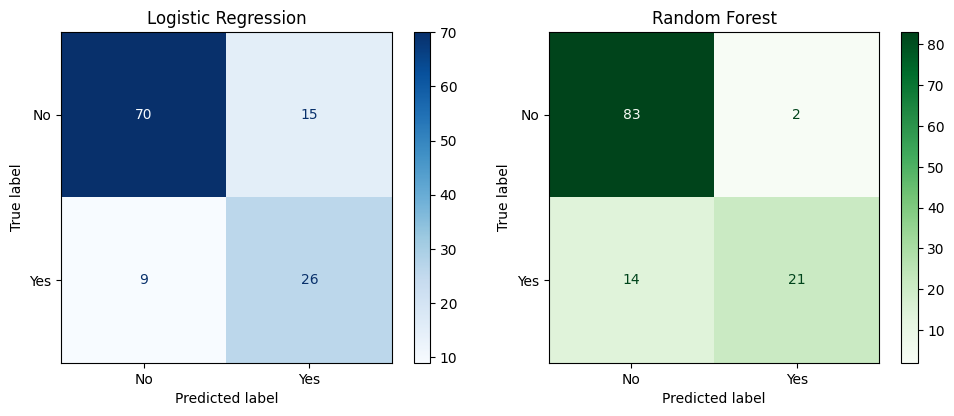

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(confusion_matrix(y_test, log_pred), display_labels=['No', 'Yes']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay(confusion_matrix(y_test, rf_pred), display_labels=['No', 'Yes']).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Random Forest')

plt.tight_layout()
plt.show()

In [42]:
print('Logistic Regression (TN, FP, FN, TP):', confusion_matrix(y_test, log_pred).ravel())
print('Random Forest       (TN, FP, FN, TP):', confusion_matrix(y_test, rf_pred).ravel())

Logistic Regression (TN, FP, FN, TP): [70 15  9 26]
Random Forest       (TN, FP, FN, TP): [83  2 14 21]


**How to read it:** TN = correctly predicted no, FP = predicted yes but actually no , FN = predicted no but actually yes, TP = correctly predicted yes.

- **Logistic Regression** found 26 of the 35 real subscribers (9 missed), but it also wrongly marked 15 non-subscribers as yes.
- **Random Forest** also found 26 of the 35 real subscribers (9 missed), but it made only 6 wrong yes predictions.

### 4.3 Comparison and recommendation



**Recommended Model: Random Forest**

- **Equally Good at Finding Subscribers:** Both models successfully find the same number of actual subscribers (26 out of 35). Selecting Random Forest won't cause us to lose out on any potential customers.
- **Far Fewer Wasted Calls:** Random Forest is much smarter. It only makes 6 accidental calls to people who aren't interested, whereas Logistic Regression makes 15. This keeps marketing costs significantly lower and keeps our customer service team more efficient.

## 5. Business Interpretation and Prediction

### 5.1 Most influential features
Permutation importance is used on the Random Forest pipeline. It shuffles one feature at a time on the test set and checks how much the F1-score drops. A bigger drop means a more important feature.

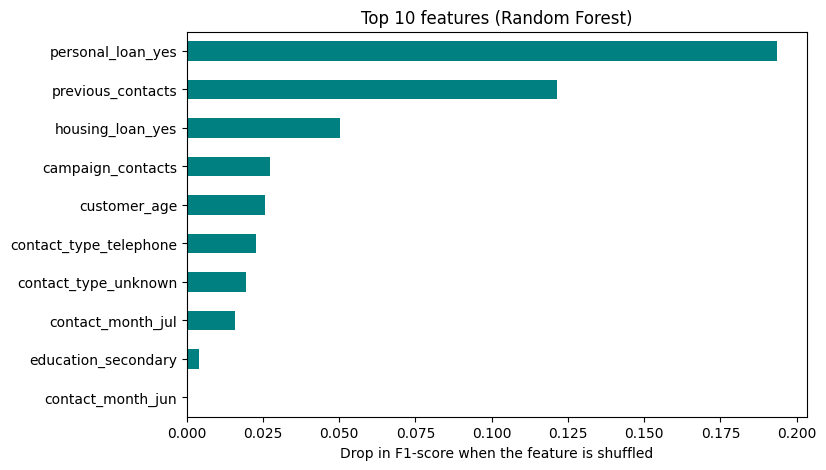

,0
personal_loan_yes,0.194
previous_contacts,0.122
housing_loan_yes,0.050
campaign_contacts,0.027
customer_age,0.026
contact_type_telephone,0.023
contact_type_unknown,0.019
contact_month_jul,0.016
education_secondary,0.004
contact_month_jun,0.000


In [43]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf_model, X_test, y_test, scoring='f1', n_repeats=10, random_state=42)

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

importance.head(10).sort_values().plot(kind='barh', figsize=(8, 5), color='teal')
plt.xlabel('Drop in F1-score when the feature is shuffled')
plt.title('Top 10 features (Random Forest)')
plt.show()

importance.head(10).round(3)

**Key Insights:**
- **Loans and Past Contacts Matter Most:** Having a personal loan, previous contacts, and a housing loan are the strongest predictors of whether someone will subscribe. This closely aligns with our initial data observations.

- **Correlation is not Causation:** These features are strong predictors, but they don't necessarily "cause" a customer to subscribe.
- **Data Splitting:** Because categorical values (like job or contact type) are split into separate columns, their individual impact can appear slightly diluted in this chart.
- **Small Test Set:** With only 120 test rows, these rankings might shift slightly with a different train-test split.

### 5.2 Predictions for five test customers

In [44]:
sample = X_test.head(5)

sample_result = df.loc[sample.index, ['customer_age', 'job', 'housing_loan', 'personal_loan']].copy()
sample_result['actual'] = y_test.head(5).map({0: 'no', 1: 'yes'})
sample_result['predicted'] = pd.Series(rf_model.predict(sample), index=sample.index).map({0: 'no', 1: 'yes'})
sample_result['prob_yes'] = rf_model.predict_proba(sample)[:, 1].round(2)

sample_result

,customer_age,job,housing_loan,personal_loan,actual,predicted,prob_yes
269,54,blue-collar,yes,no,no,no,0.26
70,18,admin,yes,yes,yes,yes,0.78
376,57,management,no,no,yes,no,0.22
543,64,services,no,yes,yes,yes,0.72
429,23,admin,no,no,no,no,0.04


### 5.3 Business conclusion

I recommend the Random Forest model. On the test set it gave an accuracy of 0.88, a precision of 0.81 and an F1-score of 0.78, better than Logistic Regression, while finding the same number of subscribers (recall 0.74). It wastes far fewer calls (6 false alarms compared with 15), which lowers the campaign cost. Both models still miss 9 likely subscribers, which is a lost sale each time, so the bank should call the customers with the highest predicted probability first, especially those with loans and previous contacts. As a next step, I would tune the Random Forest hyperparameters with cross-validation and try a lower probability threshold to catch more subscribers.